## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

In [76]:
import numpy as np
import pandas as pd

def createData(noise,N=50):
  np.random.seed(100)

  X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
  X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
  X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])

  gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
  gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
  gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
  df = pd.concat([gdf1,gdf2,gdf3],axis=0)
  return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

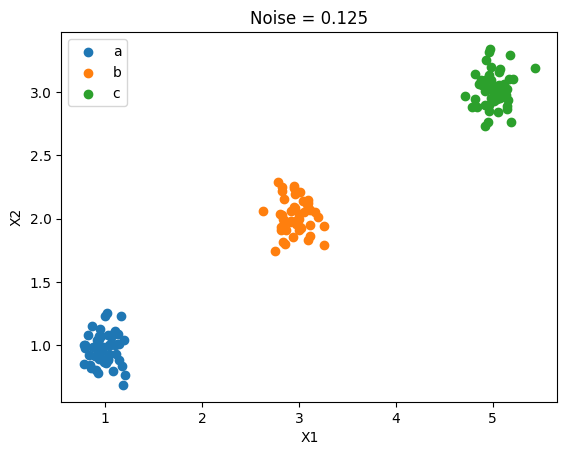

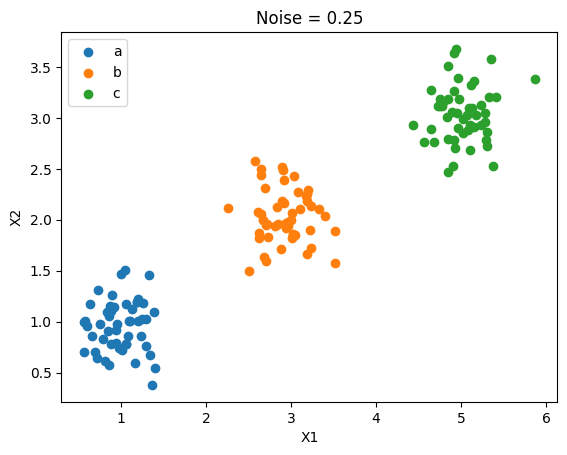

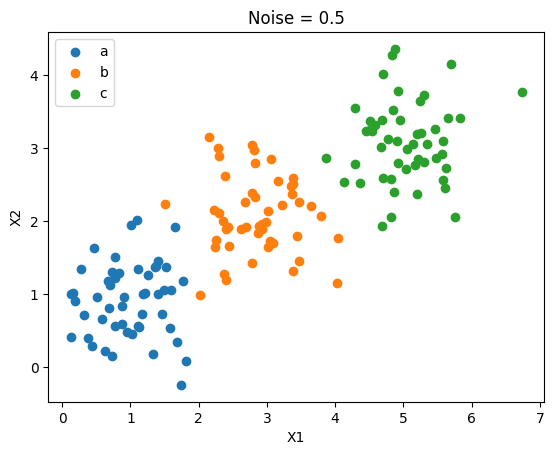

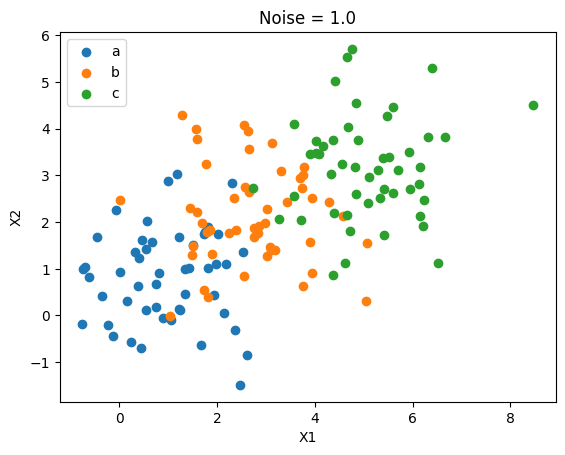

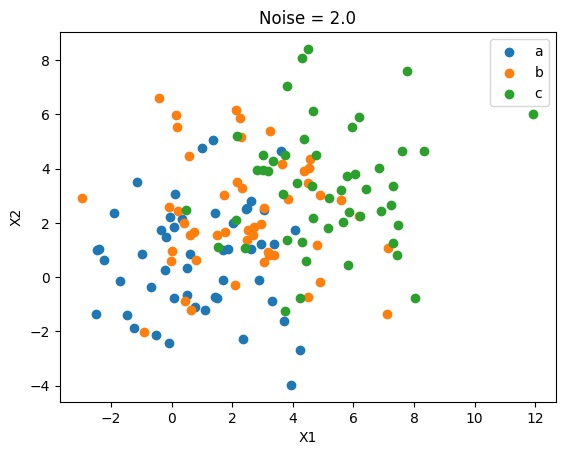

In [77]:
#Question 1.2


import matplotlib.pyplot as plt

for df, noise in zip([df0_125, df0_25, df0_5, df1_0, df2_0],
 [0.125, 0.25, 0.5, 1.0, 2.0]):
    for group in ['a', 'b', 'c']:
        data = df[df['group'] == group]
        plt.scatter(data['x1'], data['x2'], label=group)

    plt.title(f"Noise = {noise}")
    plt.xlabel("X1")
    plt.ylabel("X2")
    plt.legend()
    plt.show()


#As the noise increases from 0.125 to 2.0, the clusters become more spread out and overlap more.
#At low noise levels the clusters are clearly separated, but at higher noise levels its harder to distinguish between the groups without the labelling.

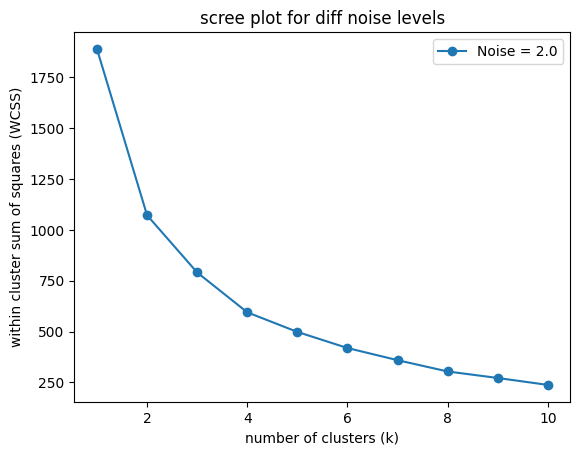

In [78]:
# Question 1.3
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

datasets = [df0_125, df0_25, df0_5, df1_0, df2_0]
noises = [0.125, 0.25, 0.5, 1.0, 2.0]

for df, noise in zip(datasets, noises):
  X = df[['x1', 'x2']]
  wcss = []

for k in range(1, 11):
  model = KMeans(n_clusters=k, random_state=100, n_init=10)
  model.fit(X)
  wcss.append(model.inertia_)

plt.plot(range(1, 11), wcss, marker='o', label=f'Noise = {noise}')

plt.xlabel('number of clusters (k)')
plt.ylabel('within cluster sum of squares (WCSS)')
plt.title('scree plot for diff noise levels')
plt.legend()
plt.show()

#As noise increases, the wcss values increase because the points are more spread out.
#At low noise levels, the scree plot has a clearer elbow shape, suggesting three clusters.
#As noise increases, the elbow becomes less distinct, which makes it harder to determine the best value of.

In [79]:
# Question 1.4
#The elbow method looks for the point where adding more clusters stops making a big difference in reducing the wcss.
#For this graph/data, the elbow is around k=3 since the data was created with three groups.
#Adding clusters before k=3 reduced the wcss, but adding more clusters after that only reduced it a little.
#As the noise increases, the elbow becomes less clear because the groups overlap more, making it harder to choose the best k.

In [80]:
# Question 2.1


import pandas as pd

df = pd.read_csv('SIPRI Military Expenditure Database.csv')

df = df[df['Year'] == 2020]
df = df.dropna()

df = df.drop(columns=['index', 'Year', 'Country'])

df.head()

#Further cleaning is needed. I would remove the country name, year, and index columns because they aren't useful for clustering.
#I would also make sure the military spending variables are numeric and standardize them before clustering so that variables with larger values don't have more influence just because of their scale.

df.shape[0]

148

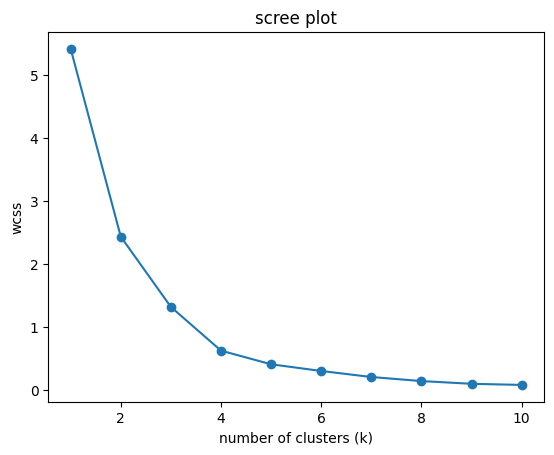

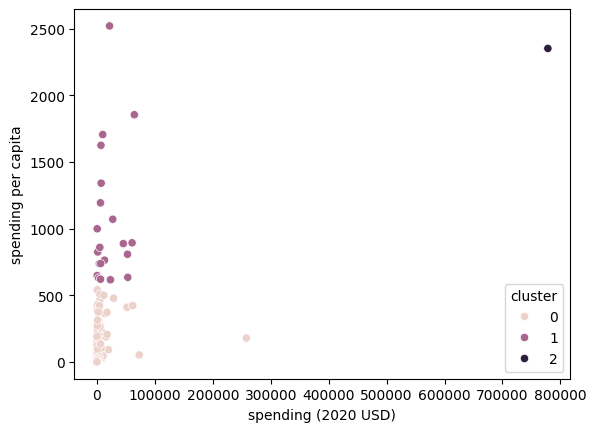

        Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                     126.0    5943.346303  24858.961064       8.622460   
1                      21.0   19975.991473  21749.736747     405.790494   
2                       1.0  778397.200000           NaN  778397.200000   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0           162.761743     580.758315    3225.333414  257973.429834   
1          4980.428135    7269.880030   27300.894701   64558.400000   
2        778397.200000  778397.200000  778397.200000  778397.200000   

        Spending per Capita                                        \
                      count         mean         std 

In [81]:
#Question 2.2

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans

df = pd.read_csv('SIPRI Military Expenditure Database.csv')
df = df[df['Year'] == 2020].dropna().copy()

X = df[['Spending (2020 USD)', 'Spending per Capita']]
X_scaled = MinMaxScaler().fit_transform(X)

wcss = []
for k in range(1, 11):
  model = KMeans(n_clusters=k, random_state=100, n_init=10)
  model.fit(X_scaled)
  wcss.append(model.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('number of clusters (k)')
plt.ylabel('wcss')
plt.title('scree plot')
plt.show()

k = 3

df['cluster'] = KMeans(n_clusters=k, random_state=100, n_init=10).fit_predict(X_scaled)

sns.scatterplot(data=df, x='Spending (2020 USD)',y='Spending per Capita', hue='cluster')
plt.xlabel('spending (2020 USD)')
plt.ylabel('spending per capita')
plt.show()

print(df.groupby('cluster')[['Spending (2020 USD)','Spending per Capita']].describe())

print(df[df['Country'] == 'United States of America'][['Country','Spending (2020 USD)','Spending per Capita','cluster']])


#The scree plot shows an elbow around k=3/k=4, so I chose k=3.
#The scatterplot shows that most countries are in cluster 0, which has lower military spending and spending per capita.
#Cluster 1 has fewer countries with higher spending per capita, and cluster 2 contains only one country with much higher total military spending than the others.
#The United States is probably in cluster 2 because it has very high military spending.
#The clusters show that countries with similar military spending patterns tend to be grouped together, while countries with high/different spending patterns can form their own cluster.


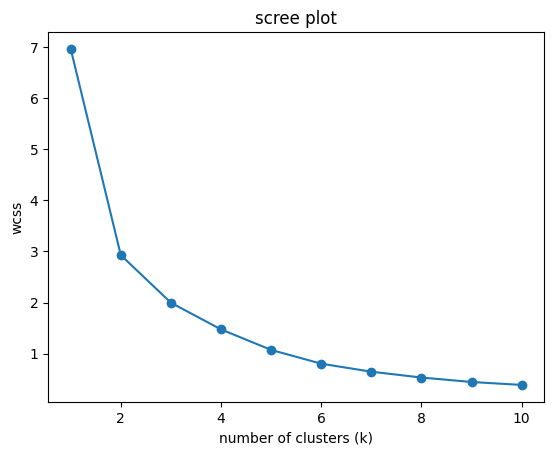

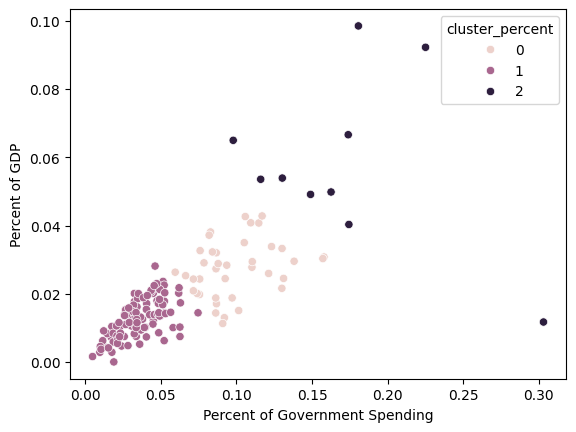

In [82]:
# Question 2.3

import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

cols = ['Percent of Government Spending', 'Percent of GDP']

X = df[cols].apply(pd.to_numeric, errors='coerce')
X = X.replace([np.inf, -np.inf], np.nan).dropna()

df_percent = df.loc[X.index].copy()

X_scaled = MinMaxScaler().fit_transform(X)

wcss = []
for k in range(1, 11):
  model = KMeans(n_clusters=k, random_state=100, n_init=10)
  model.fit(X_scaled)
  wcss.append(model.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('number of clusters (k)')
plt.ylabel('wcss')
plt.title('scree plot')
plt.show()

df_percent['cluster_percent'] = KMeans(n_clusters=3, random_state=100, n_init=10).fit_predict(X_scaled)

sns.scatterplot(data=df_percent,
                x=cols[0],
                y=cols[1],
                hue='cluster_percent')
plt.show()

#Compared to part 2, where I used total military spending and spending per capita, these are focused more on military spending as a percentage of government spending and GDP.
#The scree plot shows that 4 clusters could be a good choice because the curve starts to level off after that, but I used 3 clusters to keep it consistent with part 2.
#The scatterplot shows that most countries have low percentages for both variables, while a few countries have higher values/outliers.
#Compared to part 2, the variables show how much of a country's government spending and economy goes toward the military instead of the total amount of money spent.
#This creates a different distribution of countries.

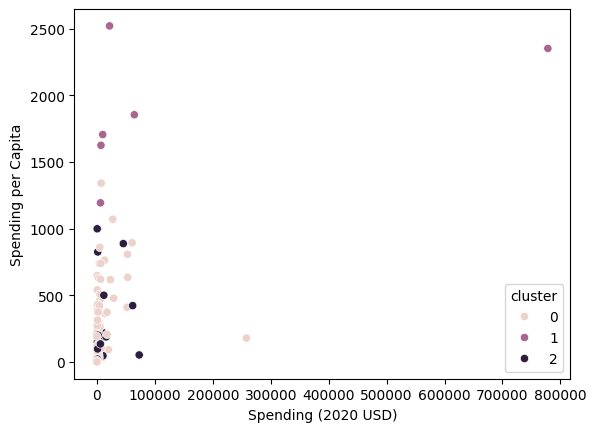

In [83]:
# Question 2.4

X = df[['Spending (2020 USD)', 'Spending per Capita','Percent of Government Spending', 'Percent of GDP']].dropna()

X_scaled = MinMaxScaler().fit_transform(X)

df_all = df.loc[X.index].copy()
df_all['cluster'] = KMeans(n_clusters=3, random_state=100, n_init=10).fit_predict(X_scaled)

sns.scatterplot(data=df_all, x='Spending (2020 USD)',y='Spending per Capita', hue='cluster')

plt.show()

#Using all four variables combines the info from the last two parts because it takes the amount countries spend on their military and the percent of government spending and GDP.
#Most countries are grouped closer to the lower spending values, and some countries have higher spending per capita or a lot higher total military spending.
#Compared to the previous parts, using all four variables has more information when grouping countries and this can lead to different cluster assignments.
#Overall, I think this would give a more complete comparison of military spending patterns.

In [84]:
#The K-means clustering algorithm found some useful patterns in military spending.
#It showed me that most countries have relatively low total military spending, while a smaller group spends much more.
#It also showed that countries can differ in spending per capita and in the percent of government spending and GDP devoted to the military.
#Clustering helped identify similarities and differences between countries, although it didn't not explain why the differences exist.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Jhanvi Patel

**Date:** 10/14/2026

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** a8c47de961058bbb661a376cec65a117f152789f


- **AI tool and model used:** Claude Sonnet 5.5

### *Prompts used



1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.


```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

```

Make scatterplots of the points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?


this is my code + answer, can u check it


```
#Question 1.2


import matplotlib.pyplot as plt

for df, noise in zip([df0_125, df0_25, df0_5, df1_0, df2_0],
 [0.125, 0.25, 0.5, 1.0, 2.0]):
    for group in ['a', 'b', 'c']:
        data = df[df['group'] == group]
        plt.scatter(data['x1'], data['x2'], label=group)

    plt.title(f"Noise = {noise}")
    plt.xlabel("X1")
    plt.ylabel("X2")
    plt.legend()
    plt.show()


#As the noise increases from 0.125 to 2.0, the clusters become more spread out and overlap more.
#At low noise levels the clusters are clearly separated, but at higher noise levels its harder to distinguish between the groups without the labelling.
```

2. 2. 2. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a . (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)

this is my answer:
```
# Question 1.3
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

datasets = [df0_125, df0_25, df0_5, df1_0, df2_0]
noises = [0.125, 0.25, 0.5, 1.0, 2.0]

for df, noise in zip(datasets, noises):
  X = df[['x1', 'x2']]
  wcss = []

for k in range(1, 11):
  model = KMeans(n_clusters=k, random_state=100, n_init=10)
  model.fit(X)
  wcss.append(model.inertia_)

plt.plot(range(1, 11), wcss, marker='o', label=f'Noise = {noise}')

plt.xlabel('number of clusters (k)')
plt.ylabel('within cluster sum of squares (WCSS)')
plt.title('scree plot for diff noise levels')
plt.legend()
plt.show()

#As noise increases, the wcss values increase because the points are more spread out.
#At low noise levels, the scree plot has a clearer elbow shape, suggesting three clusters.
#As noise increases, the elbow becomes less distinct, which makes it harder to determine the best value of.

can u check
```

3. 2. Explain the intuition of the elbow, using this numerical simulation as an example.Explain the intuition of the elbow, using this numerical simulation as an example.

this is my answer: # Question 1.4
The elbow method looks for the point where adding more clusters stops making a big difference in reducing the wcss.
For this graph/data, the elbow is around k=3 since the data was created with three groups.
Adding clusters before k=3 reduced the wcss, but adding more clusters after that only reduced it a little.
As the noise increases, the elbow becomes less clear because the groups overlap more, making it harder to choose the best k.


#QUESTION 2:

Q2. This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
Q2. This question is a case study on clustering.

Load the SIPRI Military Expenditure Database.csv file in the ./data folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?


this is my work:


```
# Question 2.1


import pandas as pd

df = pd.read_csv('SIPRI Military Expenditure Database.csv')

df = df[df['Year'] == 2020]
df = df.dropna()

df = df.drop(columns=['index', 'Year', 'Country'])

df.head()

#Further cleaning is needed. I would remove the country name, year, and index columns because they aren't useful for clustering.
#I would also make sure the military spending variables are numeric and standardize them before clustering so that variables with larger values don't have more influence just because of their scale.

df.shape[0]
```

2.

1. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?Max-min normalize Spending (2020 USD) and Spending per Capita. Use a scree plot to determine the optimal number of clusters for the  means clustering algorithm. Make a scatter plot of Spending (2020 USD) and Spending per Capita, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. .groupby(cluster).describe()). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?


this is my answer for this one:


```
#Question 2.2

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans

df = pd.read_csv('SIPRI Military Expenditure Database.csv')
df = df[df['Year'] == 2020].dropna().copy()

X = df[['Spending (2020 USD)', 'Spending per Capita']]
X_scaled = MinMaxScaler().fit_transform(X)

wcss = []
for k in range(1, 11):
  model = KMeans(n_clusters=k, random_state=100, n_init=10)
  model.fit(X_scaled)
  wcss.append(model.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('number of clusters (k)')
plt.ylabel('wcss')
plt.title('scree plot')
plt.show()

k = 3

df['cluster'] = KMeans(n_clusters=k, random_state=100, n_init=10).fit_predict(X_scaled)

sns.scatterplot(data=df, x='Spending (2020 USD)',y='Spending per Capita', hue='cluster')
plt.xlabel('spending (2020 USD)')
plt.ylabel('spending per capita')
plt.show()

print(df.groupby('cluster')[['Spending (2020 USD)','Spending per Capita']].describe())

print(df[df['Country'] == 'United States of America'][['Country','Spending (2020 USD)','Spending per Capita','cluster']])


#The scree plot shows an elbow around k=3/k=4, so I chose k=3.
#The scatterplot shows that most countries are in cluster 0, which has lower military spending and spending per capita.
#Cluster 1 has fewer countries with higher spending per capita, and cluster 2 contains only one country with much higher total military spending than the others.
#The United States is probably in cluster 2 because it has very high military spending.
#The clusters show that countries with similar military spending patterns tend to be grouped together, while countries with high/different spending patterns can form their own cluster.
```


1. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?


```
# Question 2.3

import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

cols = ['Percent of Government Spending', 'Percent of GDP']

X = df[cols].apply(pd.to_numeric, errors='coerce')
X = X.replace([np.inf, -np.inf], np.nan).dropna()

df_percent = df.loc[X.index].copy()

X_scaled = MinMaxScaler().fit_transform(X)

wcss = []
for k in range(1, 11):
  model = KMeans(n_clusters=k, random_state=100, n_init=10)
  model.fit(X_scaled)
  wcss.append(model.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('number of clusters (k)')
plt.ylabel('wcss')
plt.title('scree plot')
plt.show()

df_percent['cluster_percent'] = KMeans(n_clusters=3, random_state=100, n_init=10).fit_predict(X_scaled)

sns.scatterplot(data=df_percent,
                x=cols[0],
                y=cols[1],
                hue='cluster_percent')
plt.show()

#Compared to part 2, where I used total military spending and spending per capita, these are focused more on military spending as a percentage of government spending and GDP.
#The scree plot shows that 4 clusters could be a good choice because the curve starts to level off after that, but I used 3 clusters to keep it consistent with part 2.
#The scatterplot shows that most countries have low percentages for both variables, while a few countries have higher values/outliers.
#Compared to part 2, the variables show how much of a country's government spending and economy goes toward the military instead of the total amount of money spent.
#This creates a different distribution of countries.
```



4. 1. Use k means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?


```
# Question 2.4

X = df[['Spending (2020 USD)', 'Spending per Capita','Percent of Government Spending', 'Percent of GDP']].dropna()

X_scaled = MinMaxScaler().fit_transform(X)

df_all = df.loc[X.index].copy()
df_all['cluster'] = KMeans(n_clusters=3, random_state=100, n_init=10).fit_predict(X_scaled)

sns.scatterplot(data=df_all, x='Spending (2020 USD)',y='Spending per Capita', hue='cluster')

plt.show()

#Using all four variables combines the info from the last two parts because it takes the amount countries spend on their military and the percent of government spending and GDP.
#Most countries are grouped closer to the lower spending values, and some countries have higher spending per capita or a lot higher total military spending.
#Compared to the previous parts, using all four variables has more information when grouping countries and this can lead to different cluster assignments.
#Overall, I think this would give a more complete comparison of military spending patterns.


is this ok

```



### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Reviewing plotting code for correctness and clarity issues.
Your code is correct and runs as intended. Your answer is also correct, but it’s vague, so I’d tighten it.
Code
The loop and the per-group filtering are right, and you get one scatterplot per dataset, colored by group, with titles and labels.
Because each plot is its own figure, matplotlib autoscales the axes separately. At noise = 0.125 the axes cover roughly 0 to 6, and at noise = 2.0 they stretch much wider. That makes the clusters look more similar in size across plots than they really are. Setting the same limits on every plot (for example plt.xlim(-5, 11) and plt.ylim(-5, 9)) makes the growing spread easier to see. Or use subplots with sharex=True, sharey=True, as in the code I gave you.
Optionally, add alpha=0.7 to plt.scatter so overlapping points stay visible at high noise.
Answer
What you wrote is right, but “more spread out and overlap more” would get only partial credit if the question wants specifics. I’d add:
The cluster centers are fixed at (1,1), (3,2), and (5,3), so only the spread changes.
At 0.125 and 0.25, the clusters are tight, well separated blobs. At 0.5, they’re wider but still distinct.
At 1.0, the clusters overlap noticeably, especially the middle group with its neighbors.
At 2.0, the spread is larger than the distance between centers, so the points look like one diffuse blob and the clusters are visually indistinguishable.
The takeaway is that clusters are easy to see when the spread within them is small relative to the distance between them, and that gets harder as noise increases.


2. Your answer has a code bug, but the written conclusions are right.

**Code bug: indentation**

The inner `for k in range(1, 11)` loop and the `plt.plot(...)` call are outdented, so they sit outside the outer `for df, noise in zip(...)` loop. Python therefore runs the outer loop only to set `X` and `wcss = []`, which leaves you with the last dataset (noise = 2.0). You get one curve instead of five. The fix is to indent everything under the outer loop:

```python
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

datasets = [df0_125, df0_25, df0_5, df1_0, df2_0]
noises = [0.125, 0.25, 0.5, 1.0, 2.0]

for df, noise in zip(datasets, noises):
    X = df[['x1', 'x2']]
    wcss = []
    for k in range(1, 11):
        model = KMeans(n_clusters=k, random_state=100, n_init=10)
        model.fit(X)
        wcss.append(model.inertia_)
    plt.plot(range(1, 11), wcss, marker='o', label=f'Noise = {noise}')

plt.xlabel('Number of clusters (k)')
plt.ylabel('Within-cluster sum of squares (WCSS)')
plt.title('Scree plots for different noise levels')
plt.legend()
plt.show()
```

I ran this, and the plots are saved as `q1_3_scree.png`. The left panel is raw WCSS, which is what your code produces. The right panel divides each curve by its k = 1 value so the shapes are easier to compare. The WCSS values for k = 1 to 5 are:

| noise | k=1 | k=2 | k=3 | k=4 | k=5 |
|---|---|---|---|---|---|
| 0.125 | 511.6 | 128.9 | 4.9 | 4.3 | 3.8 |
| 0.25 | 533.3 | 142.7 | 19.7 | 17.3 | 15.1 |
| 0.5 | 606.6 | 186.8 | 77.8 | 67.2 | 58.7 |
| 1.0 | 873.7 | 361.6 | 254.9 | 210.1 | 176.1 |
| 2.0 | 1889.2 | 1071.8 | 790.5 | 594.5 | 498.2 |

**Your written answer**

Both of your points hold up, but I'd make them more specific:

1. **WCSS rises with noise.** This is true at every k. At k = 3, it goes from about 5 to about 790.
2. **A clear elbow appears at low noise.** At 0.125 and 0.25, WCSS drops sharply from k = 2 to k = 3 and then barely changes (4.9 to 4.3 to 3.8 at 0.125). That's a sharp elbow at k = 3.
3. **The elbow fades as noise rises.** At 0.5 the elbow is still visible but softer. At 1.0 and 2.0 the curve drops smoothly with no sharp bend, so you can't definitively pick k. At 2.0 the drop from k = 3 to k = 4 (about 196) is almost as large as the drop from k = 2 to k = 3 (about 281).
4. **Mention the vertical axis.** The question says to watch it. On raw WCSS, the low-noise curves look flat and similar because the noise = 2.0 curve dominates the scale. The normalized panel fixes that.

There is also a typo in your last line, "best value of." It should say "best value of k."

A short version of your answer could read:

```python
# As noise increases, WCSS increases at every k because points are more spread out around
# their centers. At low noise (0.125, 0.25) the scree plot has a sharp elbow at k = 3,
# after which WCSS barely decreases. At 0.5 the elbow is weaker, and at 1.0 and 2.0 the
# curve declines smoothly with no clear bend, so the scree plot alone can't definitively
# identify k = 3. Noise therefore makes the true number of clusters harder to determine.
```

3. Your answer is correct, but it describes the elbow without explaining why it appears. The question asks for the intuition, so that’s the part to add.
What to fix or add
Why the curve drops sharply up to k = 3. With fewer than 3 clusters, k-means has to lump distinct groups together, so many points end up far from their assigned center. In the low-noise data, going from k = 1 to 2 cuts WCSS from about 512 to 129, and going from 2 to 3 cuts it to about 5. Each added cluster separates groups that really are different.
Why it flattens after k = 3. Once each true group has its own cluster, extra clusters only split a blob that is already tight, so they only fit random noise. At noise = 0.125, the WCSS goes from 4.9 to 4.3 to 3.8 for k = 3, 4, 5, which is a tiny change.
WCSS always decreases as k rises. At k = n (every point its own cluster), WCSS is 0. So the goal isn’t the lowest WCSS. It’s the point where the improvement per added cluster stops being worth it.
Your sentence “the elbow is around k = 3 since the data was created with three groups” is slightly circular. The elbow is evidence that the data has three clusters, so it’s better to say the elbow appears at 3 because that’s where the structure in the data is used up.
Tighten the last point. At high noise the within-group spread is comparable to the distance between groups, so splitting a cluster still reduces WCSS by a meaningful amount. At noise = 2.0, the drop from k = 3 to k = 4 (about 196) is nearly as large as the drop from k = 2 to k = 3 (about 281), so no sharp bend appears.

#QUESTION 2

1. Your answer is on the right track, but it's missing the most important cleaning step, and one detail in your code needs fixing.

**What I found in the data**

After filtering to 2020 and dropping missing values, I get 148 countries, which matches yours. The four numeric variables are on wildly different scales and are heavily right-skewed:

| variable | min | median | max | skew |
|---|---|---|---|---|
| Spending (2020 USD, millions) | 8.6 | 960 | 778,397 | 10.2 |
| Percent of GDP | 0.00005 | 0.015 | 0.098 | 2.4 |
| Percent of Govt Spending | 0.005 | 0.047 | 0.303 | 1.9 |
| Spending per Capita | 0.58 | 81.5 | 2,520 | 2.9 |

There are no duplicate countries, no zeros or negatives, and no aggregate rows (like "World" or "Africa") in the 2020 data, so none of those need cleaning. The variables are already numeric.

**What to fix in your answer**

1. **Standardizing is right, but it isn't enough on its own.** Total spending has a skew of about 10: the United States is at 778,397 against a median of about 960. Standardizing rescales the variables but keeps the skew, so a handful of countries (US, China, India, etc.) would still sit far out and dominate the distance calculations, and k-means would likely give one or two tiny clusters of outliers and one huge cluster for everyone else. The fix is to log-transform the skewed variables, especially spending and spending per capita, before standardizing. After logging, the skew of spending drops from 10.2 to 0.18, and the skew of per capita drops from 2.9 to -0.20. Percent of GDP and percent of government spending are also skewed, so log those too if you want everything on a comparable footing. This is safe because there are no zeros or negatives.
2. **Keep the country names while you clean.** Your code drops `Country`, which is fine for the clustering input, but you'll want the names later to interpret which countries land in which cluster. Better to set them aside as the index or in a separate variable.
3. **Tidy the code.** `df.shape[0]` on its own line just prints 148, so add a `print` or a comment saying so. You also only need to drop `index`, `Year`, and `Country` for the model input, not from the main DataFrame.

**Suggested version**

```python
# Question 2.1
import pandas as pd
import numpy as np

df = pd.read_csv('SIPRI Military Expenditure Database.csv')
df = df[df['Year'] == 2020].dropna()
print(df.shape[0])  # 148 countries

# Keep country names as the index, drop columns not useful for clustering
df = df.set_index('Country').drop(columns=['index', 'Year'])

df.head()

# Further cleaning is needed:
# 1. Drop the index and year columns (identifiers, not features) and keep Country as the
#    row label rather than a feature, so clusters can be interpreted later.
# 2. The four variables are on very different scales (spending is in the hundreds of
#    thousands, percent of GDP is under 0.1), so they need to be standardized, otherwise
#    the large-scale variables would dominate the distance calculations.
# 3. The variables are also heavily right-skewed (total spending has skew around 10, driven
#    by countries like the US and China), so standardizing alone would leave a few outliers
#    dominating the clusters. Log-transforming first (all values are positive) reduces the
#    skew, and then standardizing puts the variables on a common scale.
```

You can add the actual transform in the next part with `np.log(df)` followed by something like `StandardScaler().fit_transform(...)`, depending on how the assignment asks you to scale.


2. Your code runs correctly, but your write-up has one claim that doesn't match the output and is missing the main comparison with part 2. I saved the plots as `q2_3.png`.

**Results from running your code**

Scree values (WCSS, k = 1 to 10): 6.96, 2.93, 2.00, 1.47, 1.07, 0.80, 0.65, 0.53, 0.45, 0.39.

With k = 3:

| cluster | countries | mean % of govt spending | mean % of GDP | examples |
|---|---|---|---|---|
| 0 | 39 | 0.099 | 0.027 | includes the United States |
| 1 | 99 | 0.036 | 0.013 | the low-burden majority |
| 2 | 10 | 0.171 | 0.058 | Oman, Saudi Arabia, Algeria, Kuwait, Azerbaijan, Israel, Armenia, Jordan, Pakistan, Belarus |

**Checking your claims**

- **"The scree plot shows 4 clusters could be a good choice because the curve levels off after that."** This is not really supported. The curve drops sharply from k = 1 to 2 (6.96 to 2.93), but after that it declines gradually (2.00, 1.47, 1.07, ...) with no clear bend at k = 4. It's more accurate to say the elbow is weak and ambiguous, with k = 3 being as reasonable as 4. This is itself a difference from part 2, where the elbow was clearer.
- **"Most countries have low percentages for both variables, while a few have higher values/outliers."** Correct. 99 of 148 countries are in the low cluster.
- **"This creates a different distribution of countries."** This is too vague and is the point to improve.

**What's different from part 2**

1. **No single outlier dominates.** In part 2, the United States sat alone because total spending was so extreme. Here, the variables are ratios with a narrow range (percent of GDP maxes out around 0.10, percent of government spending around 0.30), so the clusters are more evenly sized (99, 39, 10) rather than 126, 21, 1.
2. **The United States moves from its own cluster to a middle cluster.** Its military is large in absolute terms but a moderate share of its economy (about 3.7% of GDP and 8.2% of government spending), so it sits with the middle group in cluster 0.
3. **The high cluster is a different set of countries.** Cluster 2 here has Gulf states and countries in or near conflict or rivalry (Oman, Saudi Arabia, Algeria, Kuwait, Azerbaijan, Israel, Armenia, Jordan, Pakistan, Belarus). These are countries with a high military burden relative to their economy, not necessarily big spenders. Several of them are also not in the high cluster in part 2.
4. **The two variables are strongly related to each other**, so the points follow a rising diagonal pattern, unlike the cluttered shape of total spending versus per capita.
5. **Results depend on k.** At k = 4, the highest-burden countries split off into a group of just three (Oman, Saudi Arabia, Algeria), which shows the high cluster is not a tight group.

**Code notes**

- `df` has to be the filtered 2020 data when you run this cell. That worked for me, since I rebuilt it the same way. Your `pd.to_numeric`, `replace`, and `dropna` steps are harmless but unnecessary, since the data was already cleaned.
- Add `palette='tab10'` to `sns.scatterplot` so the integer cluster labels get distinct colors.

**Suggested write-up**

```python
# Question 2.3
# The scree plot has a sharp drop from k=1 to k=2, but after that it declines gradually,
# so the elbow is weak and ambiguous. I used k=3 to stay consistent with part 2.
#
# The scatterplot shows that most countries (99 of 148) have low values on both variables.
# A middle cluster of 39 countries (including the United States) has moderate values, and
# a small cluster of 10 countries (Oman, Saudi Arabia, Algeria, Kuwait, Azerbaijan, Israel,
# Armenia, Jordan, Pakistan, Belarus) has a high share of government spending and GDP.
#
# Compared to part 2, the results are different. Part 2 measured the size of spending, and
# the United States was so extreme that it formed its own cluster. These variables measure
# the burden of military spending relative to the economy and government, so the United
# States now falls in a middle cluster (about 3.7% of GDP and 8.2% of government spending),
# and the high cluster is made up of Gulf states and countries in or near conflict, not the
# biggest spenders. Because these variables have a narrower range, no single country
# dominates, and the clusters are more evenly sized.
```

Check the exact counts against your own output before submitting, in case your seed or settings differ.


4.

Code: It runs correctly and matches the clustering I got. I’d add palette='tab10' to the scatterplot and a second scatterplot of Percent of Government Spending vs Percent of GDP, since the first plot alone doesn’t show what separates the high-burden cluster. I’d also print the cluster means and sizes so you have numbers to cite.
Write-up: What you wrote is true but generic. Add the cluster sizes, where the United States lands, and how the result relates to parts 2 and 3. Here’s what I’d submit:
python
Question 2.4

cols = ['Spending (2020 USD)', 'Spending per Capita',
        'Percent of Government Spending', 'Percent of GDP']

X = df[cols].dropna()

X_scaled = MinMaxScaler().fit_transform(X)

df_all = df.loc[X.index].copy()
df_all['cluster'] = KMeans(n_clusters=3, random_state=100, n_init=10).fit_predict(X_scaled)

sns.scatterplot(data=df_all, x='Spending (2020 USD)', y='Spending per Capita',
                hue='cluster', palette='tab10')
plt.show()

sns.scatterplot(data=df_all, x='Percent of Government Spending', y='Percent of GDP',
                hue='cluster', palette='tab10')
plt.show()

print(df_all.groupby('cluster')[cols].mean())
print(df_all['cluster'].value_counts())

Using all four variables combines the information from the last two parts, because it
uses both the amount countries spend on their military and the share of government
 spending and GDP that goes to it.
#
 Most countries (111) are in a cluster with low values on everything. A second cluster of
 31 countries (including India) has a high share of government spending and GDP going to
 the military but only moderate total spending. A third cluster of 6 countries (the United
 States, Saudi Arabia, Israel, Singapore, Kuwait, Oman) has very high total spending, per
 capita spending, and military burden.
#
Compared to the previous parts, the United States is no longer in a cluster by itself as
 in part 2, because it is grouped with other countries that also have high per capita
 spending and burden. The groups also mix the size-based clusters from part 2 and the
 burden-based clusters from part 3, so no single scatterplot separates them cleanly.
 Overall, using all four variables gives a more complete picture of military spending
 patterns, though the scree plot has no clear elbow, so the choice of k is more uncertain.
Before submitting, run it and check that your cluster sizes (111, 31, 6) and the United States grouping match the write-up. If your output differs, update the numbers to match.


5. Your answer is reasonable, and the last sentence, that clustering doesn’t explain why the differences exist, is a good point to keep. It’s a little generic, though, and has one typo. “didn’t not explain” should be “didn’t explain.”
What to add
Specific patterns from your results. Most countries (about 100 or more, depending on the part) sit in a low-spending cluster, and a few countries stand out. In part 2, the United States was alone in its own cluster. In part 3, the high-burden group was Gulf states and countries in or near conflict (Oman, Saudi Arabia, Algeria, Kuwait, Israel, and others), not the biggest spenders.
Total size and burden are different things. China and India have huge total spending but low per capita spending and a moderate burden, so they are not in the “high” clusters on the other measures. This is the most useful insight.
Limitations. The results depend on the choice of k (the scree plots had weak elbows, especially with all four variables), on scaling (max-min scaling let the United States dominate part 2), and on which variables you use.


### *Evaluation of AI suggestions


I accepted the revisions for 1.3, 1.4, 2.1, 2.2, 2.4, 2.5

For 1.3, I realized my graph didn't have all five components and Claude caught that, so I was able to fix that as needed. For 1.4, Claude refined a bit of my wording, so I accepted that. For 2.1, Claude fixed my explanations, and I decided it was good to incorporate into my answer. For 2.2, I chose to incorporate some of claude's explanations into mine. For 2.4 and 2.5, I used some of the wording claude gave me to better emphasize what I wanted to talk about, which was useful.

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [85]:
# Your Phase 2 solution to the problem goes here.


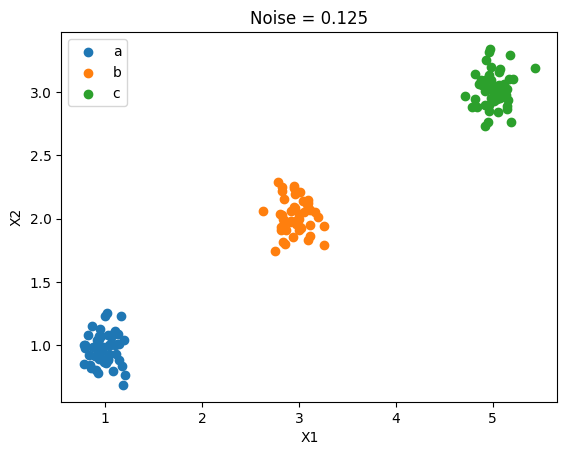

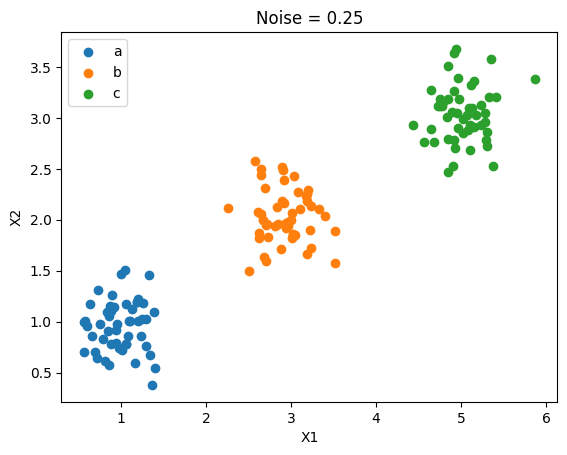

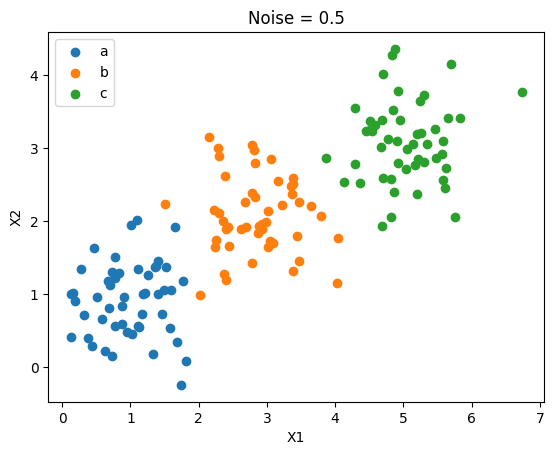

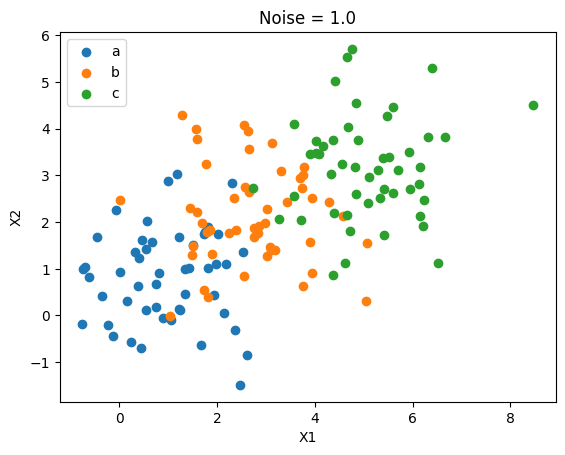

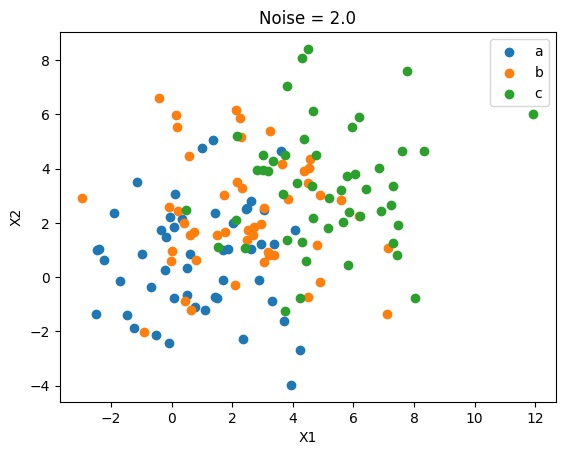

In [86]:
#Question 1.2


import matplotlib.pyplot as plt

for df, noise in zip([df0_125, df0_25, df0_5, df1_0, df2_0],
 [0.125, 0.25, 0.5, 1.0, 2.0]):
    for group in ['a', 'b', 'c']:
        data = df[df['group'] == group]
        plt.scatter(data['x1'], data['x2'], label=group)

    plt.title(f"Noise = {noise}")
    plt.xlabel("X1")
    plt.ylabel("X2")
    plt.legend()
    plt.show()


#As the noise increases from 0.125 to 2.0, the clusters become more spread out and overlap more.
#At low noise levels the clusters are clearly separated, but at higher noise levels its harder to distinguish between the groups without the labelling.

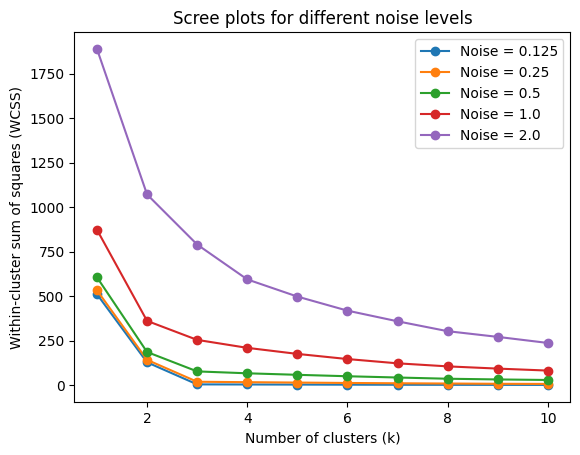

In [87]:
#Question 1.3

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

datasets = [df0_125, df0_25, df0_5, df1_0, df2_0]
noises = [0.125, 0.25, 0.5, 1.0, 2.0]

for df, noise in zip(datasets, noises):
    X = df[['x1', 'x2']]
    wcss = []
    for k in range(1, 11):
        model = KMeans(n_clusters=k, random_state=100, n_init=10)
        model.fit(X)
        wcss.append(model.inertia_)
    plt.plot(range(1, 11), wcss, marker='o', label=f'Noise = {noise}')

plt.xlabel('Number of clusters (k)')
plt.ylabel('Within-cluster sum of squares (WCSS)')
plt.title('Scree plots for different noise levels')
plt.legend()
plt.show()

#As noise increases, the wcss values increase because the points are more spread out.
#At low noise levels, the scree plot has a clearer elbow shape, suggesting three clusters.
#As noise increases, the elbow becomes less distinct, which makes it harder to determine the best value of.

In [88]:
#Question 1.4

# The elbow method looks for the point where adding more clusters stops making a big
# difference in reducing the WCSS. WCSS always decreases as k increases (it reaches 0 when
# every point is its own cluster), so the goal isn't the lowest WCSS but the k where the
# improvement stops being worth it.
#
# For this data, the elbow is at k = 3, which matches the three groups the data was created
# with. Before k = 3, k-means has to merge distinct groups, so many points sit far from
# their assigned centers and each added cluster reduces the WCSS a lot (at noise = 0.125,
# from about 512 at k = 1 to 129 at k = 2 to 5 at k = 3). After k = 3, each true group
# already has its own cluster, so extra clusters only split groups that are already tight
# and fit random noise rather than real structure, which reduces the WCSS only a little
# (4.9, 4.3, 3.8 for k = 3, 4, 5). The sharp bend at k = 3 is where the real structure in
# the data has been used up.
#
# As the noise increases, the elbow becomes less clear because the groups overlap more and
# are more spread out internally. Splitting a cluster still reduces the WCSS by a
# meaningful amount even past k = 3 (at noise = 2.0, the drop from k = 3 to 4 is about 196,
# close to the drop of about 281 from k = 2 to 3). The curve declines smoothly with no
# sharp bend, which makes it harder to choose the best k.

In [89]:
#Question 2.1

import pandas as pd
import numpy as np

df = pd.read_csv('SIPRI Military Expenditure Database.csv')
df = df[df['Year'] == 2020].dropna()
print(df.shape[0])

df = df.set_index('Country').drop(columns=['index', 'Year'])

df.head()

# Further cleaning is needed:
# 1. Need to drop the index and year columns (identifiers, not features) and keep Country as the
#    row label rather than a feature, so clusters can be interpreted later.
# 2. The four variables are on very different scales (spending is in the hundreds of
#    thousands, percent of GDP is under 0.1), so they need to be standardized, otherwise
#    the large-scale variables would dominate the distance calculations.
# 3. The variables are also heavily right-skewed (total spending has skew around 10, driven
#    by countries like the US and China), so standardizing alone would leave a few outliers
#    dominating the clusters. Log-transforming first (all values are positive) reduces the
#    skew, and then standardizing puts the variables on a common scale.

148


,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
Country,,,,
Afghanistan,279.576955,0.013589,0.049728,7.181899
Albania,187.433234,0.012583,0.037952,65.126211
Algeria,9708.277440,0.066600,0.173924,221.392384
Angola,993.594405,0.014442,0.074624,30.231680
Argentina,2830.929705,0.007269,0.017268,62.636731


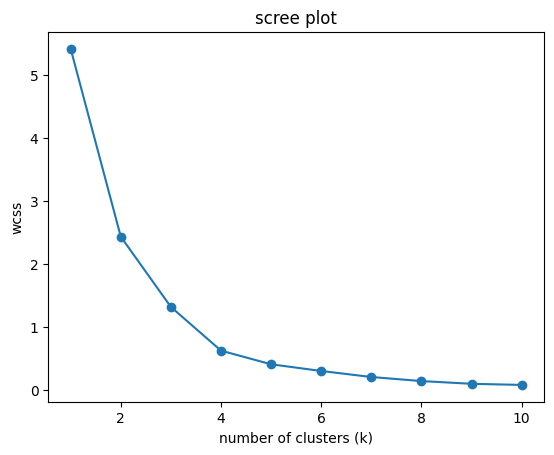

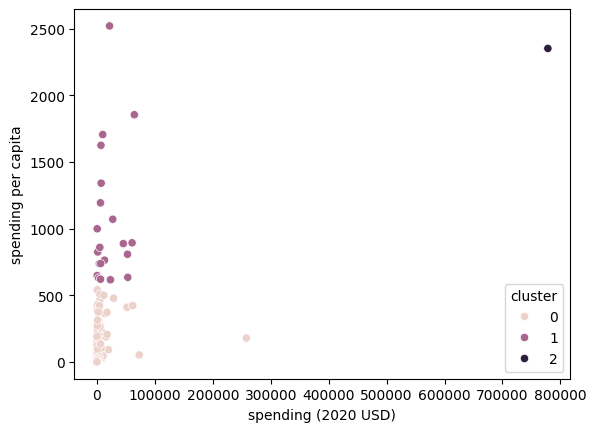

        Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                     126.0    5943.346303  24858.961064       8.622460   
1                      21.0   19975.991473  21749.736747     405.790494   
2                       1.0  778397.200000           NaN  778397.200000   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0           162.761743     580.758315    3225.333414  257973.429834   
1          4980.428135    7269.880030   27300.894701   64558.400000   
2        778397.200000  778397.200000  778397.200000  778397.200000   

        Spending per Capita                                        \
                      count         mean         std 

In [90]:
#Question 2.2

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans

df = pd.read_csv('SIPRI Military Expenditure Database.csv')
df = df[df['Year'] == 2020].dropna().copy()

X = df[['Spending (2020 USD)', 'Spending per Capita']]
X_scaled = MinMaxScaler().fit_transform(X)

wcss = []
for k in range(1, 11):
  model = KMeans(n_clusters=k, random_state=100, n_init=10)
  model.fit(X_scaled)
  wcss.append(model.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('number of clusters (k)')
plt.ylabel('wcss')
plt.title('scree plot')
plt.show()

k = 3

df['cluster'] = KMeans(n_clusters=k, random_state=100, n_init=10).fit_predict(X_scaled)

sns.scatterplot(data=df, x='Spending (2020 USD)',y='Spending per Capita', hue='cluster')
plt.xlabel('spending (2020 USD)')
plt.ylabel('spending per capita')
plt.show()

print(df.groupby('cluster')[['Spending (2020 USD)','Spending per Capita']].describe())

print(df[df['Country'] == 'United States of America'][['Country','Spending (2020 USD)','Spending per Capita','cluster']])

# The scree plot has an elbow around k=3/k=4, so I chose k=3.
#
# Cluster 0 holds most countries (126 of 148), with low total spending and low spending per
# capita. Cluster 1 has 21 countries with high spending per capita (e.g., Saudi Arabia, UK,
# Germany, Israel, Singapore, Norway, Kuwait). Cluster 2 contains only the United States,
# whose total spending (about 778 billion USD) is far above every other country's. Max-min
# scaling puts it at 1 while almost everyone else is compressed near 0, so it is an
# extreme outlier.
#
# Pattern: total and per capita spending don't always go together. China has very high
# total spending but low per capita spending, so it is in cluster 0, while cluster 1 is
# mostly wealthy or security-focused countries with high per capita spending.

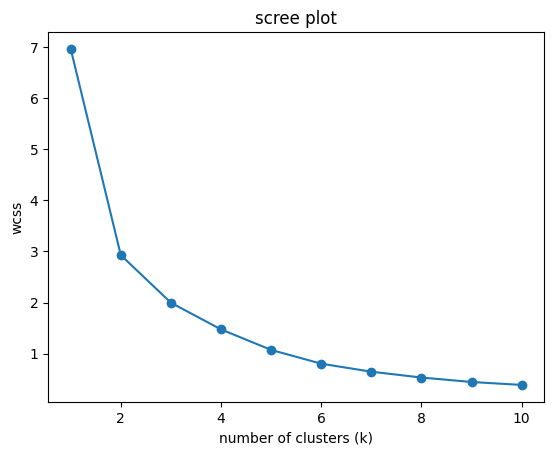

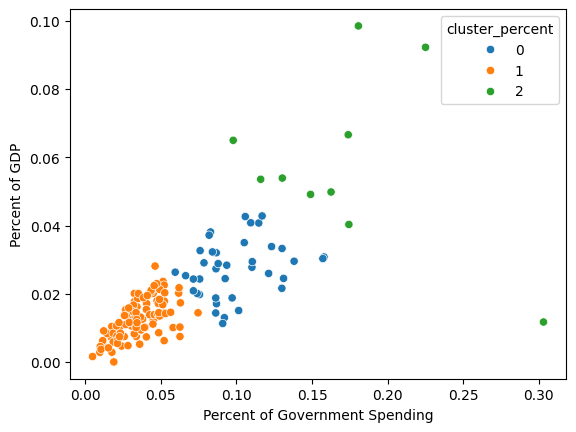

                Percent of Government Spending                                \
                                         count      mean       std       min   
cluster_percent                                                                
0                                         39.0  0.098683  0.024125  0.059520   
1                                         99.0  0.035777  0.014549  0.004896   
2                                         10.0  0.171289  0.058725  0.097882   

                                                        Percent of GDP  \
                      25%       50%       75%       max          count   
cluster_percent                                                          
0                0.082430  0.092044  0.112633  0.157918           39.0   
1                0.025921  0.034261  0.047402  0.074624           99.0   
2                0.135010  0.168248  0.179081  0.303027           10.0   

                                                                          

In [91]:
# Question 2.3

import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

cols = ['Percent of Government Spending', 'Percent of GDP']

X = df[cols].apply(pd.to_numeric, errors='coerce')
X = X.replace([np.inf, -np.inf], np.nan).dropna()

df_percent = df.loc[X.index].copy()

X_scaled = MinMaxScaler().fit_transform(X)

wcss = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('number of clusters (k)')
plt.ylabel('wcss')
plt.title('scree plot')
plt.show()

df_percent['cluster_percent'] = KMeans(n_clusters=3, random_state=100, n_init=10).fit_predict(X_scaled)

sns.scatterplot(data=df_percent,
                x=cols[0],
                y=cols[1],
                hue='cluster_percent',
                palette='tab10')
plt.show()

print(df_percent.groupby('cluster_percent')[cols].describe())
print(df_percent[df_percent['Country'] == 'United States of America'][['Country'] + cols + ['cluster_percent']])

# The scree plot drops from k=1 to k=2 but then declines gradually, so the elbow is
# weak and ambiguous (k=3 or 4 are both reasonable). I used k=3 to stay consistent with part 2.
#
# The scatterplot shows that most countries (99 of 148) have low percentages on both
# variables. A middle cluster of 39 countries (including the United States) has moderate
# values, and a small cluster of 10 countries (Oman, Saudi Arabia, Algeria, Kuwait,
# Azerbaijan, Israel, Armenia, Jordan, Pakistan, Belarus) has a high share of government
# spending and GDP going to the military.
#
# Compared to part 2, the results are different. Part 2 measured the total amount of
# spending, and the United States was such an extreme outlier that it formed its own
# cluster. These variables show how much of a country's government spending and economy
# goes toward the military, so the United States now falls in a middle cluster (about 3.7%
# of GDP and 8.2% of government spending), and the high cluster is made up of Gulf states
# and countries in or near conflict rather than the biggest spenders. Because these
# variables have a narrower range, no single country dominates and the clusters are more
# evenly sized.

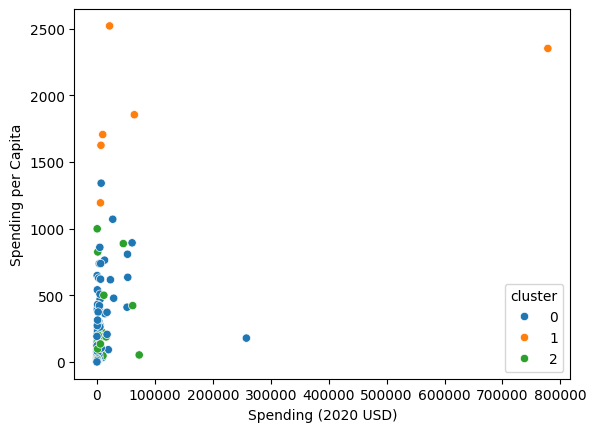

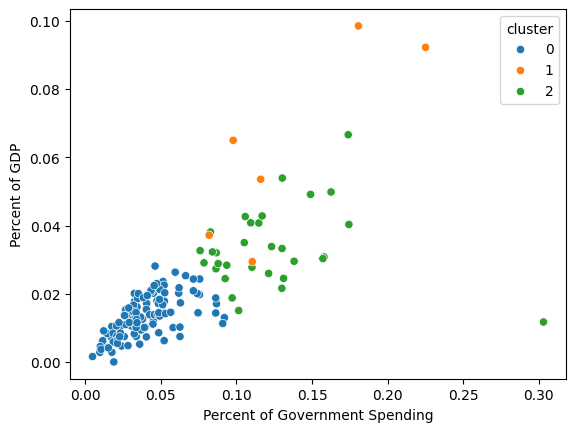

         Spending (2020 USD)  Spending per Capita  \
cluster                                             
0                7086.472777           196.926833   
1              147964.582042          1875.150751   
2                8786.086602           212.689100   

         Percent of Government Spending  Percent of GDP  
cluster                                                  
0                              0.040350        0.013419  
1                              0.135351        0.062634  
2                              0.122985        0.033492  
cluster
0    111
2     31
1      6
Name: count, dtype: int64


In [96]:
# Question 2.4

cols = ['Spending (2020 USD)', 'Spending per Capita','Percent of Government Spending', 'Percent of GDP']

X = df[cols].dropna()

X_scaled = MinMaxScaler().fit_transform(X)

df_all = df.loc[X.index].copy()
df_all['cluster'] = KMeans(n_clusters=3, random_state=100, n_init=10).fit_predict(X_scaled)

sns.scatterplot(data=df_all, x='Spending (2020 USD)', y='Spending per Capita',
                hue='cluster', palette='tab10')
plt.show()

sns.scatterplot(data=df_all, x='Percent of Government Spending', y='Percent of GDP',
                hue='cluster', palette='tab10')
plt.show()

print(df_all.groupby('cluster')[cols].mean())
print(df_all['cluster'].value_counts())

# Using all four variables combines the information from the last two parts, because it
# uses both the amount countries spend on their military and the share of government
# spending and GDP that goes to it.

# Most countries are in a cluster with low values on everything. A second cluster of
# 31 countries have a high share of government spending and GDP going to
# the military but only moderate total spending. A third cluster of 6 countries have very high total spending, per
# capita spending, and military burden.

# Compared to the previous parts, the United States is no longer in a cluster by itself as
# in part 2, because it is grouped with other countries that also have high per capita
# spending and burden. The groups also mix the size-based clusters from part 2 and the
# burden-based clusters from part 3, so no single scatterplot separates them cleanly.
# Overall, using all four variables gives a more complete picture of military spending
# patterns, though the scree plot has no clear elbow, so the choice of k is more uncertain.

In [97]:
# Question 2.5

# Yes, the K-means clustering found some useful patterns in military spending.
#
# It showed that most countries have relatively low spending on every measure, while a
# small group spends much more. It also showed that total spending and military burden
# are different things: the United States was an extreme outlier on total spending
# (alone in its own cluster in part 2), but the countries with the highest share of
# GDP and government spending going to the military were mostly Gulf states and countries
# in or near conflict. Countries like
# China and India have very high total spending but low per capita spending and a moderate
# burden. Using all four variables combined these views, so the groupings reflect both
# the size of spending and how much of the economy it takes up.
#
# However, clustering only describes similarities and differences; it doesn't explain why
# they exist. The results also depend on choices like the number of clusters (the scree
# plots had weak elbows) and the scaling (max-min scaling let the United States dominate
# in part 2), so the clusters should be treated as a starting point for further analysis
# rather than definitive groupings.

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]


I think the main improvements claude was able to do was improve the quality of my explanations and was able to catch any small mistakes in my code that I may have missed. Overall, I was able to fix a lot of things because of claude and I think it helped me learn different ways to solve the same problem protentially, which was definetely helpful. I think using AI to go over problems and correct code is a great way to use it.